### Apply CellVADIS to tissue immune cell atlas (TICA)

preprocessed data can be obtained from the original publication at [https://www.tissueimmunecellatlas.org/](https://www.tissueimmunecellatlas.org/).

[Direct download link](https://cellgeni.cog.sanger.ac.uk/pan-immune/t-cells.h5ad)

In [1]:
# Notebook setup
# Load analysis dependencies and import the local CellVADIS package.
# The autoreload extension is useful while iterating on package code in a notebook.
import anndata as ad
import scanpy as sc
import numpy as np
# autoreload

%load_ext autoreload    
%autoreload 2
import CellVADIS
import harmonypy as hm

path_data = "docs/data/"
# Load the preprocessed T-cell atlas available in the repository.
adata = ad.read_h5ad(path_data + "t-cells.h5ad")

## 1. Data loading and preprocessing

We start from a preprocessed AnnData object containing T-cell profiles across tissues and donors.

The next few steps:
- identify highly variable genes,
- compute PCA,
- correct donor-specific batch effects with Harmony,
- store the batch-corrected embedding for downstream OT analysis.

This step is important because OT is run on a cleaned latent representation rather than directly on raw expression values.


Number of highly variable genes: 1557


2026-10-23 17:31:21,159 - harmonypy - INFO - Running Harmony
2026-10-23 17:31:21,159 - harmonypy - INFO -   Parameters:
2026-10-23 17:31:21,159 - harmonypy - INFO -     max_iter_harmony: 10
2026-10-23 17:31:21,159 - harmonypy - INFO -     max_iter_kmeans: 4
2026-10-23 17:31:21,160 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-10-23 17:31:21,160 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-10-23 17:31:21,161 - harmonypy - INFO -     nclust: 100
2026-10-23 17:31:21,161 - harmonypy - INFO -     block_size: 0.05
2026-10-23 17:31:21,161 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-10-23 17:31:21,161 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
2026-10-23 17:31:21,161 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-10-23 17:31:21,162 - harmonypy - INFO -     verbose: True
2026-10-23 17:31:21,162 - harmonypy - INFO -     random_state: 0
2026-10-23 17:31:21,162 - harmonypy - INFO -   Data: 50 PCs × 216611 cells
2026-10-23 17:31:21

(216611, 50)


2026-10-23 17:31:21,382 - harmonypy - INFO - Iteration 1 of 10
2026-10-23 17:31:21,500 - harmonypy - INFO - Iteration 2 of 10
2026-10-23 17:31:21,631 - harmonypy - INFO - Iteration 3 of 10
2026-10-23 17:31:21,762 - harmonypy - INFO - Iteration 4 of 10
2026-10-23 17:31:21,899 - harmonypy - INFO - Iteration 5 of 10
2026-10-23 17:31:22,029 - harmonypy - INFO - Converged after 5 iterations
/home/wickerlw/Projects/CellVADIS/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


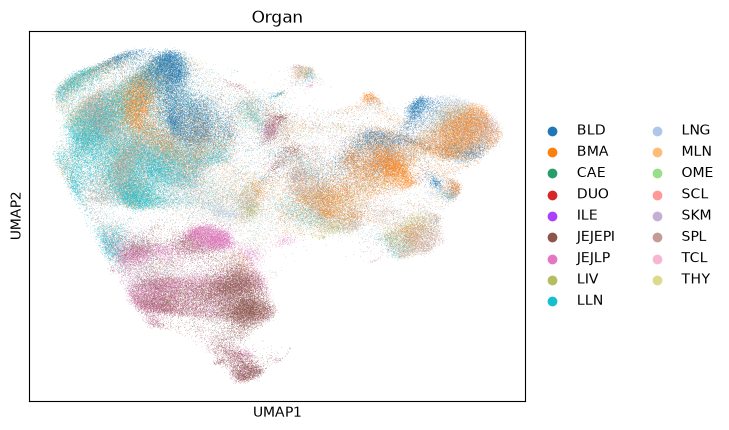

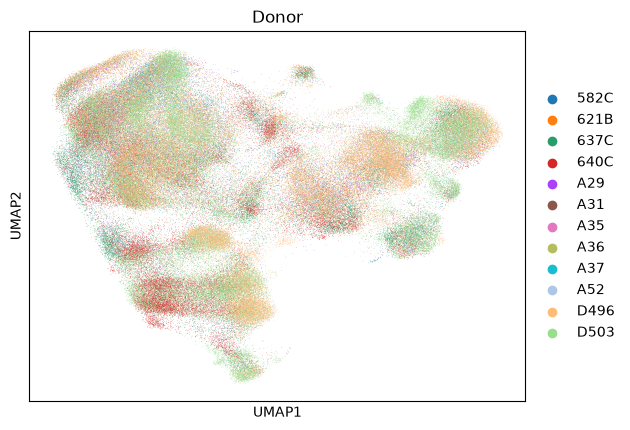

In [2]:
# Identify highly variable genes and build a donor-corrected latent space.
# This keeps only the most informative genes and removes donor-specific effects before OT.
sc.pp.highly_variable_genes(adata, batch_key="Donor")
print(f"Number of highly variable genes: {np.sum(adata.var['highly_variable'])}")

# Compute PCA and harmonize the embedding across donors.
sc.tl.pca(adata, random_state=0)
# Get PCs from the AnnData object
pcs = adata.obsm["X_pca"]
print(pcs.shape)  # (n_cells, n_pcs)

# Run Harmony on the PCA embedding
harmony_out = hm.run_harmony(pcs, adata.obs, "Donor")

# Store corrected PCs back in the AnnData object
adata.obsm["X_pca_harmony"] = harmony_out.Z_corr

# Compute a 2D UMAP in the corrected embedding and visualize the major tissue structure.
sc.pp.neighbors(adata, use_rep="X_pca_harmony", random_state=0)
sc.tl.umap(adata, random_state=0)
sc.pl.umap(adata, color=["Organ"], wspace=0.4, show=True)
sc.pl.umap(adata, color=["Donor"], wspace=0.4, show=True)

# Remove uninformative or highly variable but biologically noisy genes such as ribosomal and mitochondrial markers.
adata.var.loc[
    adata.var_names.str.startswith(("RPS", "RPL", "MT-", "HSP", "HLA")),
    "highly_variable",
] = False
# Make sure location information is stored in the location column expected by CellVADIS.
adata.obs["location"] = adata.obs["Organ"]

## 2. Fate inference with CellVADIS

The source compartment is defined as blood-derived cells, while the target locations are the tissues of interest.

The CellVADIS models are intended to estimate the likelihood that a source cell traffics to each target tissue. The decision wether to use StitchOT or JointOT depends on the downstream tasks. \
 As a general guideline we recommend using JointOT for anything related to the target tissue cells, so correlation with their marginal weights, computing homing niches etc.. \
 StitchOT might therefore be preferred for tasks involving individual source cells, e.g. fate correlations of blood cells.


The downstream visualizations below summarize how strongly each source cell contributes to each target tissue and where those fates are concentrated in latent space.


In [3]:
# Define the source and target compartments for fate inference.
# Here, blood is treated as the source and the selected tissues are treated as target destinations.
# Subsampling is important so that tissues with many more cells do not dominate the OT solution.
adata_OT = adata.copy()

organs_to_keep = (
    adata_OT.obs["Organ"]
    .value_counts()[adata_OT.obs["Organ"].value_counts() > 1000]
    .index
)
adata_OT = adata_OT[adata_OT.obs["Organ"].isin(organs_to_keep)]
print(adata_OT.obs["Organ"].value_counts())


target_names = ["MLN", "LLN", "SPL", "JEJEPI", "JEJLP", "BMA", "LNG", "LIV"]
colors = [
    "#0072B2",
    "#56b4e9",
    "#E69F00",
    "#009E73",
    "#00C76E",
    "#CC79A7",
    "#F0E442",
    "mediumpurple",
]
source_name = "BLD"
# We strongly suggest subsampling the data to an equal number of cells per target tissue,
# as otherwise mass distributions may be biased toward tissues with larger sample size.
adata_OT = CellVADIS.utils.obs_key_wise_subsampling(
    adata_OT, obs_keys=["Organ"], N_target=2000, N_source=5000, source_name="BLD"
)

# Apply both CellVADIS methods, results get stored in the AnnData object in 2 .uns keys, one for each method.
# By default the key is "stitchOT" for the StitchOT method and "jointOT" for the JointOT method.
CellVADIS.JointOT(
    adata=adata_OT,
    obsm_key="X_pca_harmony",
    source_name=source_name,
    target_names=target_names,
    store_in_adata=True,
)

CellVADIS.StitchOT(
    adata=adata_OT,
    obsm_key="X_pca_harmony",
    source_name=source_name,
    target_names=target_names,
    store_in_adata=True,
    tau_a=0.5,
    tau_b=0.995,
)

print(adata_OT.obs["Organ"].value_counts())

Organ
LLN       45319
SPL       38727
BMA       29178
JEJEPI    26574
BLD       20333
JEJLP     17590
MLN       17148
LIV       10011
LNG        8852
Name: count, dtype: int64
Organ
BLD       5000
BMA       2000
JEJEPI    2000
JEJLP     2000
LIV       2000
LLN       2000
LNG       2000
MLN       2000
SPL       2000
Name: count, dtype: int64


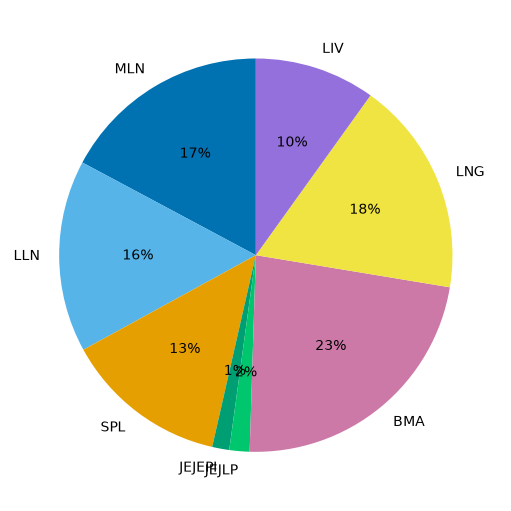

array([0.17191356, 0.15790881, 0.13454803, 0.0140261 , 0.01659537,
       0.2288784 , 0.17705156, 0.09907816])

In [4]:
# Summarize the overall tissue-level contribution pattern across all source cells.
CellVADIS.plotting.plot_tissue_transition_proportions(
    adata_OT, return_proportions=True, colors=colors
)

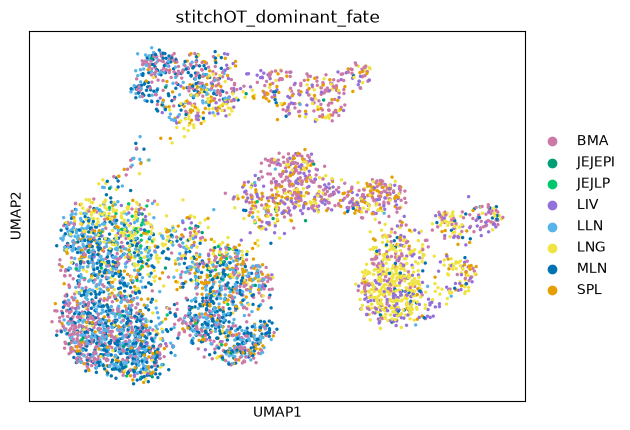

In [5]:
CellVADIS.plotting.plot_dominant_fates(
    adata_OT, output_key="stitchOT", return_fig=False, colors=colors
)

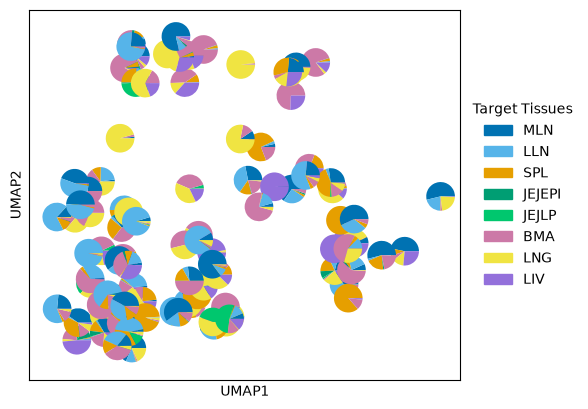

In [6]:
fig = CellVADIS.plotting.plot_fate_probabilities_with_pie_charts(
    adata_OT,
    output_key="stitchOT",
    s=250,
    colors=colors,
    show=True,
    return_fig=False,
)

If cell type information is available (such as in annotated scRNA-seq data), we can analyse the average cell fates per cell type

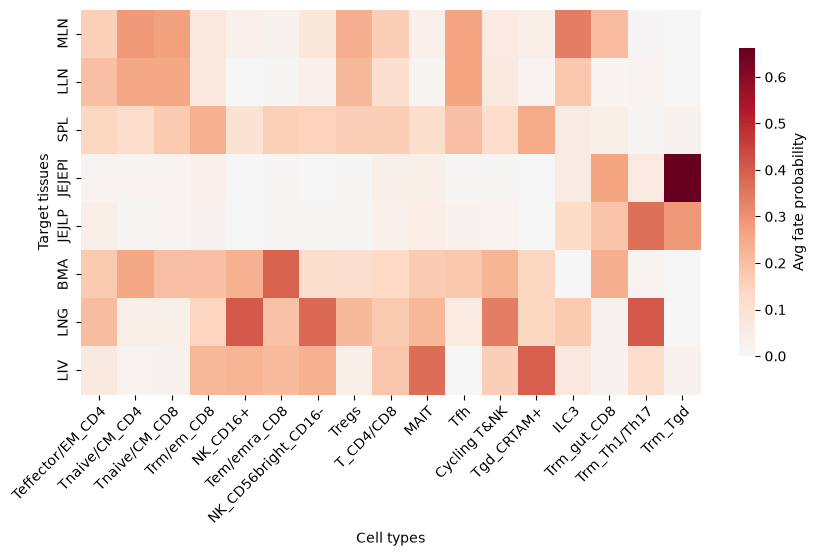

In [7]:
CellVADIS.plotting.plot_avg_fate_per_celltype(
    adata_OT, output_key="stitchOT", celltype_key="Manually_curated_celltype", show=True
)

### Identification of trafficking signatures 
by correlating fate potentials with gene expression

In [ ]:
corr_fates_markers = CellVADIS.utils.corr_marker_with_fates(
    adata_OT,
    marker_genes=["CD4", "CD8A", "FOXP3", "CCR7", "SELL", "IL7R", "GZMB", "PRF1"],
    return_as_df=True,
)

# the same but with all hvg genes
corr_fates_hvg = CellVADIS.utils.corr_marker_with_fates(
    adata_OT,
    marker_genes=adata_OT.var_names[adata_OT.var["highly_variable"]],
    return_as_df=True,
)

In [9]:
corr_fates_hvg.head(10)

,MLN,LLN,SPL,JEJEPI,JEJLP,BMA,LNG,LIV
GZMB,-0.544055,-0.686762,-0.233016,-0.590068,-0.569571,0.033168,0.365232,0.380508
GNLY,-0.577433,-0.701026,-0.223585,-0.566188,-0.532943,0.018419,0.373200,0.400281
NKG7,-0.609394,-0.737326,-0.197586,-0.576359,-0.545379,0.045822,0.385263,0.474641
FGFBP2,-0.527733,-0.645582,-0.185124,-0.562080,-0.526861,0.093383,0.326407,0.356879
KLRD1,-0.573948,-0.684070,-0.165980,-0.532356,-0.509785,0.038969,0.359722,0.438966
SPON2,-0.460982,-0.589201,-0.218270,-0.506951,-0.473198,0.009438,0.315028,0.306478
CST7,-0.577442,-0.671747,-0.177665,-0.554122,-0.503192,0.028971,0.396293,0.449747
TYROBP,-0.438736,-0.573661,-0.194833,-0.492664,-0.454560,-0.000867,0.298696,0.306970
PRF1,-0.471850,-0.594361,-0.155361,-0.523197,-0.505726,0.082486,0.290787,0.361148
ZEB2,-0.512907,-0.629666,-0.184473,-0.497285,-0.448524,0.020176,0.348163,0.397945


## Identification of homing niches

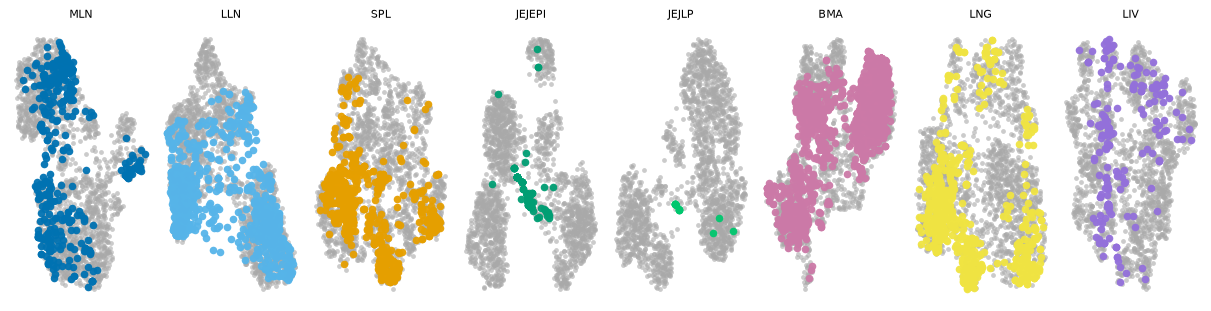

In [10]:
CellVADIS.plotting.plot_homing_niches(
    adata_OT,
    output_key="jointOT",
    colors=colors,
    figsize=(12, 3),
)

In [11]:
CellVADIS.utils.corr_marker_with_target_marginals(
    adata_OT,
    marker_genes=["CD69", "CD8A", "FOXP3", "CCR7", "SELL", "IL7R", "GZMB", "PRF1"],
    return_as_df=True,
    output_key="stitchOT",
    sort_df_by="JEJLP",
)

,MLN,LLN,SPL,JEJEPI,JEJLP,BMA,LNG,LIV
CD69,-0.293269,-0.257614,-0.232762,-0.312239,-0.433340,-0.094002,-0.224499,-0.322953
IL7R,-0.066940,0.004565,0.241034,0.089250,0.261420,0.268652,0.123980,-0.022234
CD8A,-0.127028,-0.029007,-0.162959,0.004697,-0.133675,-0.193603,-0.007423,-0.027040
CCR7,0.381374,0.135582,0.419423,0.093830,0.085297,0.482373,0.232454,0.104065
PRF1,-0.230995,-0.173788,-0.253902,-0.050998,-0.082065,-0.306484,0.101134,0.166324
SELL,0.494500,0.255735,0.342408,0.183819,0.073373,0.406235,0.210645,0.227031
FOXP3,-0.047494,-0.088547,0.038092,0.043076,-0.008850,0.084303,0.025412,0.012717
GZMB,-0.135602,-0.114795,-0.016468,0.009494,-0.001635,-0.225691,0.087170,0.275275


In [ ]:
CellVADIS.utils.corr_marker_with_target_marginals(
    adata_OT,
    marker_genes=adata_OT.var_names[adata_OT.var["highly_variable"]],
    return_as_df=True,
    output_key="stitchOT",
    sort_df_by="JEJLP",
)

,MLN,LLN,SPL,JEJEPI,JEJLP,BMA,LNG,LIV
DNAJA1,-0.293599,-0.442136,-0.429829,-0.385751,-0.579232,-0.229306,-0.295298,-0.118578
NR4A1,-0.100424,-0.316151,-0.248973,-0.322480,-0.565873,-0.093961,-0.220882,-0.162176
PPP1R15A,-0.405610,-0.430237,-0.269055,-0.399394,-0.557923,-0.162886,-0.234686,-0.202415
BAG3,0.019818,-0.215304,-0.255263,-0.396792,-0.525672,-0.035714,-0.033874,-0.020559
FOSB,-0.412729,-0.428088,-0.366281,-0.353803,-0.498570,-0.212146,-0.278002,-0.268516
...,...,...,...,...,...,...,...,...
CLDN5,0.077585,0.003785,0.064644,0.018374,NaN,0.053289,0.055870,0.017957
IGLV1-36,-0.000174,-0.001488,-0.020241,NaN,NaN,NaN,NaN,0.037394
GTSE1,-0.047890,-0.039896,-0.017360,-0.018850,NaN,-0.087068,-0.013137,0.012990
ALAS2,-0.021224,NaN,-0.010038,NaN,NaN,-0.035456,-0.038217,0.019024
